# Внешняя торговля Армении: примеры работы с базой данных

Тетрадка показывает, как работать с базой `data/armstat_trade.duckdb`, собранной из раздела
«External trade database» Армстата (<https://armstat.am/en/?nid=160>): запросы к представлениям и таблицам,
сравнения источников и визуализации.

**Запуск.** Сначала соберите базу (`make all` или `make build`), затем:

```bash
make install                          # .venv с зависимостями (dev + notebook)
.venv/bin/jupyter lab docs/examples.ipynb
make notebook                         # или: выполнить тетрадку и сохранить результаты
```

Структура базы описана в [database.md](database.md), все колонки — в [data_dictionary.md](data_dictionary.md).

Условные обозначения: стоимость в веб-базе и 4-значных файлах — **тыс. долл. США** (`value_kusd`, `export_kusd`),
в 10-значных файлах — **долл. США** (`value_usd`). 2026 год неполный (январь–сентябрь).
Под каждым графиком выводится таблица с теми же данными.

## 1. Подключение и оформление графиков

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

# корень репозитория: ищем pyproject.toml вверх от текущей папки
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
con = duckdb.connect(str(ROOT / "data" / "armstat_trade.duckdb"), read_only=True)


def sql(query: str, **params) -> pd.DataFrame:
    # Выполнить SQL и вернуть pandas.DataFrame
    return con.execute(query, params or None).df()


pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.1f}".replace(",", " "))

# Палитра: категориальные цвета в фиксированном порядке, одна последовательная шкала (синяя)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SEQ = LinearSegmentedColormap.from_list("blues", BLUES)

plt.rcParams.update({
    "figure.figsize": (10, 4.6), "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "font.family": ["Helvetica", "Arial", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-", "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "legend.frameon": False, "lines.linewidth": 1.6,
    "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlepad": 22,
})


def title(ax, head: str, sub: str) -> None:
    # Заголовок слева и подзаголовок (единицы измерения, источник) вторым рядом
    ax.set_title(head)
    ax.text(0, 1.02, sub, transform=ax.transAxes, color=INK2, fontsize=9, va="bottom")


def end_label(ax, x, y, text: str) -> None:
    # Прямая подпись в конце линии (текст — цветом текста, не цветом серии)
    ax.annotate(text, (x, y), xytext=(6, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)


thousands = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))

## 2. Что лежит в базе

Таблицы сгруппированы по префиксам: `meta_` — происхождение данных, `dim_` — справочники на трёх языках,
`db_` — факты из веб-базы, `file_` — факты из опубликованных файлов, `stg_`/`raw_` — исходные данные без потерь,
`qc_` — проверки качества, `v_` — представления.

In [2]:
sql('''
    SELECT split_part(table_name, '_', 1) AS слой, count(*) AS таблиц, sum(estimated_size)::BIGINT AS строк
    FROM duckdb_tables() WHERE schema_name = 'main'
    GROUP BY 1 ORDER BY строк DESC
''')

,слой,таблиц,строк
0,raw,1,1755060
1,stg,2,936012
2,db,2,632064
3,file,10,444158
4,dim,11,16600
5,meta,6,836
6,qc,7,724


In [3]:
# Источники: файлы по страницам и запросы к веб-базе
sql('''
    SELECT source_kind AS тип, nid, count(*) AS n, min(year) AS с, max(year) AS по,
           count(*) FILTER (WHERE NOT is_current) AS неактуальных_редакций
    FROM v_sources GROUP BY ALL ORDER BY тип, nid
''')

,тип,nid,n,с,по,неактуальных_редакций
0,file,766,8,2018,2024,1
1,file,777,10,2018,2025,2
2,file,778,11,2017,2025,3
3,web_db,148,156,1995,2026,0
4,web_db,159,162,1995,2025,0
5,web_db,717,60,2017,2026,0


### Справочники на трёх языках

Факты не зависят от языка: названия стран и товаров хранятся в справочниках (`name_en`, `name_hy`, `name_ru`).

In [4]:
sql('''
    SELECT country_code, iso_alpha2, name_en, name_hy, name_ru
    FROM dim_country WHERE country_code IN (51, 156, 643, 784, 840, 997, 998)
    ORDER BY country_code
''')

,country_code,iso_alpha2,name_en,name_hy,name_ru
0,51,NaN,Armenia,Հայաստան,Армения
1,156,CN,China,Չինաստան,Китай
2,643,RU,Russian Federation,Ռուսաստանի Դաշնություն,Россия
3,784,AE,United Arab Emirates,Արաբական Միացյալ Էմիրություններ,Обьедененные Арабские Эмираты
4,840,US,USA,ԱՄՆ,США
5,997,NaN,Individual,Ֆիզիկական անձինք,Физические лица
6,998,NaN,Unknown country,Անհայտ երկիր,Неизвестная страна


In [5]:
sql('''
    SELECT h.hs_code, h.level, h.section, s.name_ru AS раздел, h.name_en, h.name_hy, h.name_ru
    FROM dim_hs h LEFT JOIN dim_hs_section s USING (section)
    WHERE h.hs_code IN ('22', '2204', '2208', '71', '7108')
    ORDER BY h.hs_code
''')

,hs_code,level,section,раздел,name_en,name_hy,name_ru
0,22,2,IV,Готовые пищевые продукты; алкогольные и безалкогольные напитки и уксус; таба...,"Beverages, spirits and vinegar",Ալկոհոլային և ոչ ալկոհոլային խմիչքներ և քացախ,Алкогольные и безалкогольные напитки и уксус
1,2204,4,IV,Готовые пищевые продукты; алкогольные и безалкогольные напитки и уксус; таба...,"Grape wines(including fortified), alcoholic grape must","Խաղողի գինի, շամպայն","Вина виноградные натуральные, включая крепленые"
2,2208,4,IV,Готовые пищевые продукты; алкогольные и безалкогольные напитки и уксус; таба...,"Liqueur, spirits and undenatured ethyl alcohol <80%","Կոնյակ, ռոմ, ջին, օղի, լիկյոր","Спирт этиловый неденатурированный с концентрацией спирта менее 80 об.%, спир..."
3,71,2,XIV,"Жемчуг природный или культивированный, драгоценные или полудрагоценные камни...","Pearls, precious stones, precious metals","Մարգարիտ, թանկարժեք կամ կիսաթանկարժեք քարեր, թանկ. մետաղներ, մետաղներ երեսպա...","Жемчуг природный или культивированный, драгоценные или полудрагоценные камни..."
4,7108,4,XIV,"Жемчуг природный или культивированный, драгоценные или полудрагоценные камни...","Gold, unwrought, semimanufactured, powder form","Ոսկի անմշակ կամ կիսամշակ, փոշի","Золото необработанное или полуобработанное, или в виде порошка"


## 3. Динамика внешней торговли, 1995–2025

Годовые итоги по всем странам из веб-базы (`v_db_country_annual`). Для непрерывного ряда импорт берётся
**по стране отправления**: импорт по стране происхождения в базе по странам заполнен только с 2003 г.

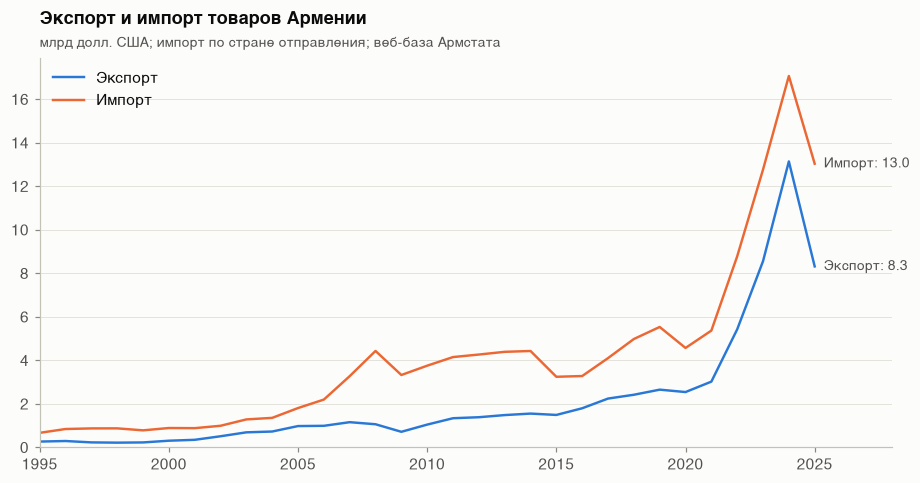

,year,export_bn,import_bn,balance_bn
23,2018,2.4,5.0,-2.6
24,2019,2.6,5.5,-2.9
25,2020,2.5,4.6,-2.0
26,2021,3.0,5.4,-2.3
27,2022,5.4,8.8,-3.4
28,2023,8.6,12.8,-4.2
29,2024,13.1,17.1,-3.9
30,2025,8.3,13.0,-4.7


In [6]:
annual = sql('''
    SELECT year,
           sum(export_kusd) / 1e6             AS export_bn,
           sum(import_consignment_kusd) / 1e6 AS import_bn,
           (sum(export_kusd) - sum(import_consignment_kusd)) / 1e6 AS balance_bn
    FROM v_db_country_annual
    WHERE year <= 2025
    GROUP BY year ORDER BY year
''')

fig, ax = plt.subplots()
for col, name, color in [("export_bn", "Экспорт", SERIES[0]), ("import_bn", "Импорт", SERIES[1])]:
    ax.plot(annual.year, annual[col], color=color, label=name)
    last = annual.iloc[-1]
    end_label(ax, last.year, last[col], f"{name}: {last[col]:.1f}")
ax.set_xlim(1995, 2028)
ax.set_xticks(range(1995, 2026, 5))
ax.set_ylim(0)
title(ax, "Экспорт и импорт товаров Армении", "млрд долл. США; импорт по стране отправления; веб-база Армстата")
ax.legend(loc="upper left")
plt.show()

annual.tail(8)

Резкий рост в 2022–2024 гг. и спад в 2025 г. — в основном реэкспорт (золото, ювелирные изделия, электроника),
см. раздел 6.

## 4. Помесячная динамика

Помесячные данные по странам есть с 2003 г. (`v_db_country_monthly`); сумма месяцев точно равна годовому значению
(проверка `qc_db_monthly_vs_annual`).

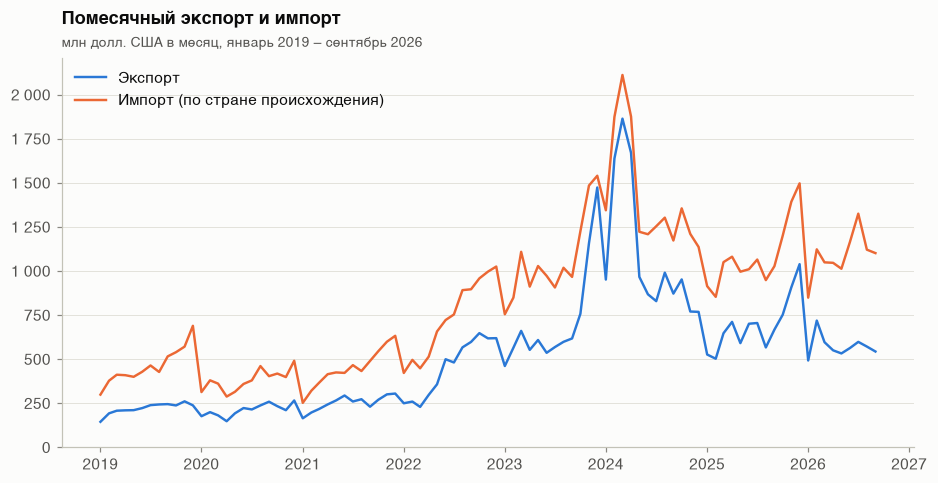

,export_musd,import_musd
год,,
2019-01-01,2 647.2,5 528.7
2020-01-01,2 537.0,4 564.0
2021-01-01,3 016.0,5 362.2
2022-01-01,5 419.1,8 775.9
2023-01-01,8 552.0,12 762.7
2024-01-01,13 136.4,17 065.1
2025-01-01,8 311.4,13 031.7
2026-01-01,5 163.1,9 790.3


In [7]:
monthly = sql('''
    SELECT period_start,
           sum(export_kusd) / 1e3        AS export_musd,
           sum(import_origin_kusd) / 1e3 AS import_musd
    FROM v_db_country_monthly
    WHERE year >= 2019
    GROUP BY period_start ORDER BY period_start
''')

fig, ax = plt.subplots()
ax.plot(monthly.period_start, monthly.export_musd, color=SERIES[0], label="Экспорт")
ax.plot(monthly.period_start, monthly.import_musd, color=SERIES[1], label="Импорт (по стране происхождения)")
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0)
title(ax, "Помесячный экспорт и импорт", "млн долл. США в месяц, январь 2019 – сентябрь 2026")
ax.legend(loc="upper left")
plt.show()

monthly.set_index("period_start").resample("YS").sum().rename_axis("год")

## 5. Торговые партнёры

### Крупнейшие направления экспорта в 2025 г.

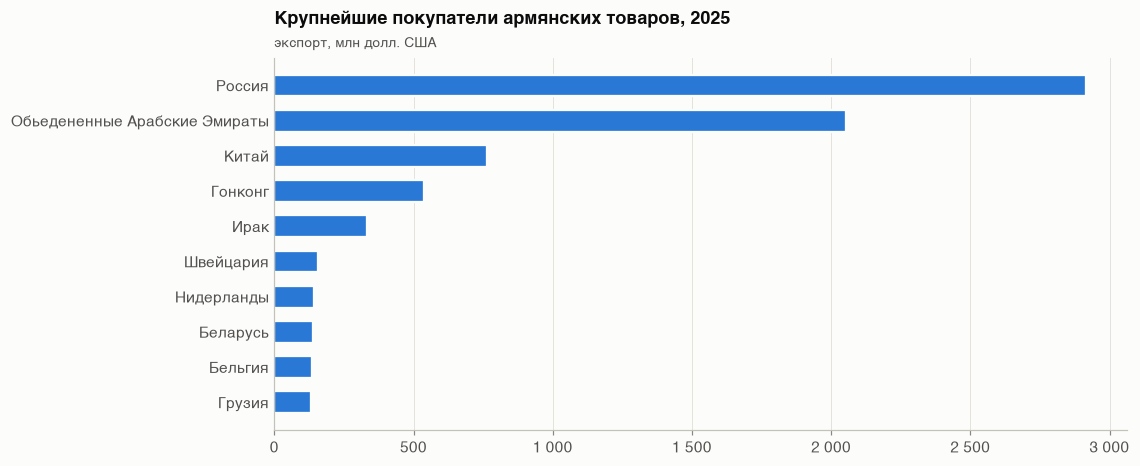

,страна,экспорт_млн,доля_проц
0,Россия,2 916.4,35.1
1,Обьедененные Арабские Эмираты,2 054.5,24.7
2,Китай,763.6,9.2
3,Гонконг,536.2,6.5
4,Ирак,331.6,4.0
5,Швейцария,156.8,1.9
6,Нидерланды,141.9,1.7
7,Беларусь,138.8,1.7
8,Бельгия,134.2,1.6
9,Грузия,133.2,1.6


In [8]:
top_partners = sql('''
    SELECT name_ru AS страна, export_kusd / 1e3 AS экспорт_млн,
           100 * export_kusd / sum(export_kusd) OVER () AS доля_проц
    FROM v_db_country_annual WHERE year = 2025
    ORDER BY export_kusd DESC LIMIT 10
''')

fig, ax = plt.subplots(figsize=(10, 4.4))
d = top_partners.iloc[::-1]
ax.barh(d["страна"], d["экспорт_млн"], height=0.62, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(thousands)
ax.tick_params(axis="y", length=0)
title(ax, "Крупнейшие покупатели армянских товаров, 2025", "экспорт, млн долл. США")
plt.show()

top_partners

### Как менялась география экспорта

Доли России, ОАЭ, Китая и Гонконга в экспорте. Цвет закреплён за страной.

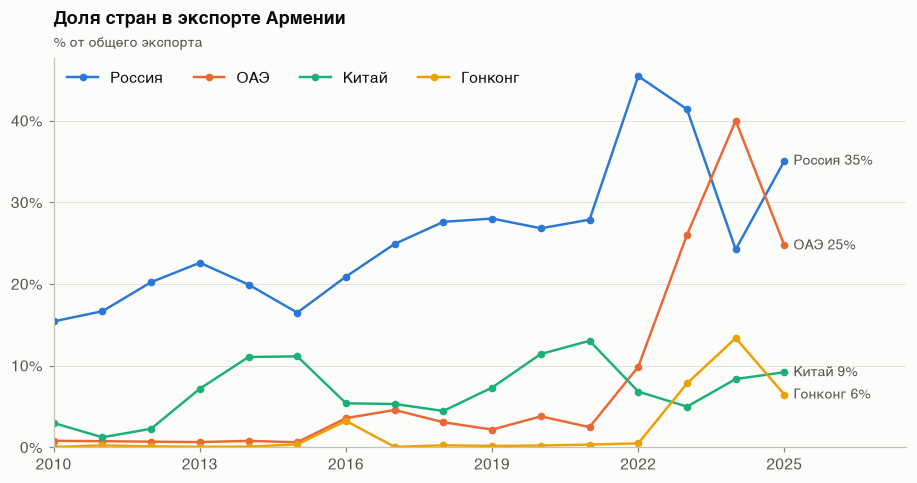

,year,Россия,ОАЭ,Китай,Гонконг
0,2010,15.4,0.8,3.0,0.0
1,2011,16.7,0.7,1.2,0.2
2,2012,20.2,0.7,2.3,0.1
3,2013,22.6,0.6,7.2,0.1
4,2014,19.9,0.8,11.1,0.1
5,2015,16.5,0.6,11.1,0.3
6,2016,20.9,3.6,5.4,3.2
7,2017,24.9,4.6,5.3,0.0
8,2018,27.6,3.1,4.4,0.2
9,2019,28.0,2.2,7.3,0.2


In [9]:
shares = sql('''
    SELECT year,
           100 * sum(export_kusd) FILTER (WHERE country_code = 643) / sum(export_kusd) AS "Россия",
           100 * sum(export_kusd) FILTER (WHERE country_code = 784) / sum(export_kusd) AS "ОАЭ",
           100 * sum(export_kusd) FILTER (WHERE country_code = 156) / sum(export_kusd) AS "Китай",
           100 * sum(export_kusd) FILTER (WHERE country_code = 344) / sum(export_kusd) AS "Гонконг"
    FROM v_db_country_annual
    WHERE year BETWEEN 2010 AND 2025
    GROUP BY year ORDER BY year
''')

fig, ax = plt.subplots()
for (name, color) in zip(["Россия", "ОАЭ", "Китай", "Гонконг"], SERIES):
    ax.plot(shares.year, shares[name], color=color, label=name, marker="o", markersize=4)
    end_label(ax, 2025, shares[name].iloc[-1], f"{name} {shares[name].iloc[-1]:.0f}%")
ax.set_xlim(2010, 2027.5)
ax.set_xticks(range(2010, 2026, 3))
ax.set_ylim(0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
title(ax, "Доля стран в экспорте Армении", "% от общего экспорта")
ax.legend(loc="upper left", ncols=4)
plt.show()

shares.round(1)

### Импорт по стране происхождения и по стране отправления

Для импорта Армстат публикует два показателя. Разница показывает транзитные цепочки: товары китайского
или турецкого производства поступают через Грузию, ОАЭ, Россию.

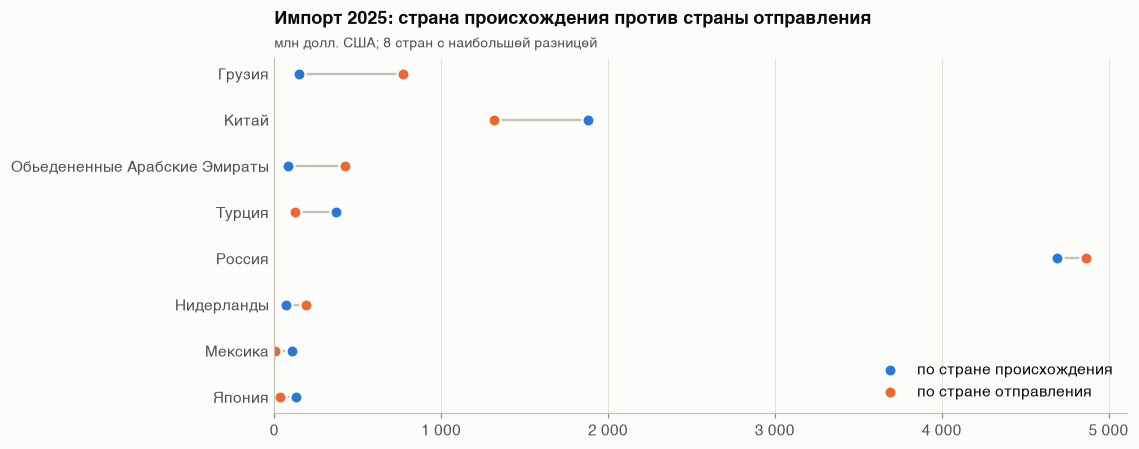

,страна,происхождение,отправление,разница
0,Грузия,146.2,773.8,-627.5
1,Китай,1 878.0,1 316.9,561.1
2,Обьедененные Арабские Эмираты,79.0,425.2,-346.2
3,Турция,368.5,121.4,247.0
4,Россия,4 691.6,4 866.0,-174.3
5,Нидерланды,69.6,191.0,-121.4
6,Мексика,103.3,1.7,101.6
7,Япония,127.9,32.2,95.7


In [10]:
origin = sql('''
    SELECT name_ru AS страна,
           import_origin_kusd / 1e3      AS происхождение,
           import_consignment_kusd / 1e3 AS отправление
    FROM v_db_country_annual
    WHERE year = 2025 AND country_code NOT IN (998)
    ORDER BY abs(import_origin_kusd - import_consignment_kusd) DESC
    LIMIT 8
''')

fig, ax = plt.subplots(figsize=(10, 4.2))
d = origin.iloc[::-1].reset_index(drop=True)
y = range(len(d))
ax.hlines(y, d["происхождение"], d["отправление"], color=AXIS, linewidth=1.5, zorder=1)
ax.scatter(d["происхождение"], y, s=64, color=SERIES[0], label="по стране происхождения",
           edgecolor=SURFACE, linewidth=1.5, zorder=2)
ax.scatter(d["отправление"], y, s=64, color=SERIES[1], label="по стране отправления",
           edgecolor=SURFACE, linewidth=1.5, zorder=2)
ax.set_yticks(list(y), d["страна"])
ax.tick_params(axis="y", length=0)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(0)
title(ax, "Импорт 2025: страна происхождения против страны отправления", "млн долл. США; 8 стран с наибольшей разницей")
ax.legend(loc="lower right")
plt.show()

origin.assign(разница=origin["происхождение"] - origin["отправление"])

## 6. Товарная структура

### Крупнейшие товарные позиции экспорта в 2025 г. (4 знака ТН ВЭД)

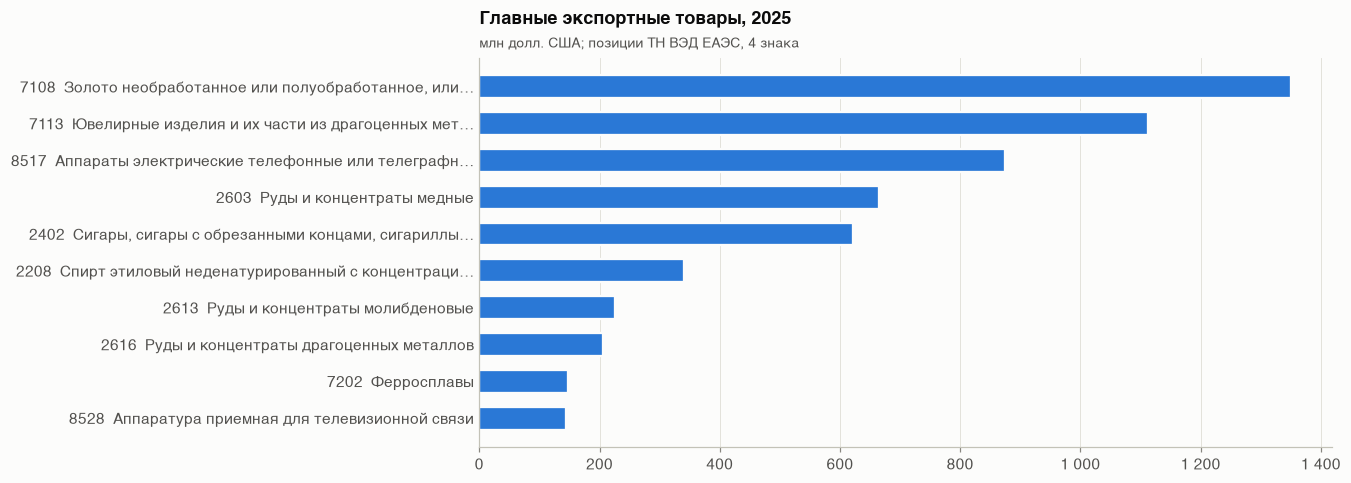

,код,позиция,экспорт_млн,доля_проц
0,7108,"Золото необработанное или полуобработанное, или в виде порошка",1 350.6,16.3
1,7113,"Ювелирные изделия и их части из драгоценных металлов или металлов, плакирова...",1 112.3,13.4
2,8517,Аппараты электрические телефонные или телеграфные для проводной связи,875.2,10.5
3,2603,Руды и концентраты медные,665.3,8.0
4,2402,"Сигары, сигары с обрезанными концами, сигариллы и сигареты из табака или его...",621.8,7.5
5,2208,"Спирт этиловый неденатурированный с концентрацией спирта менее 80 об.%, спир...",340.6,4.1
6,2613,Руды и концентраты молибденовые,225.2,2.7
7,2616,Руды и концентраты драгоценных металлов,205.3,2.5
8,7202,Ферросплавы,146.9,1.8
9,8528,Аппаратура приемная для телевизионной связи,144.4,1.7


In [11]:
top_goods = sql('''
    SELECT hs4_code AS код, name_ru AS позиция, export_kusd / 1e3 AS экспорт_млн,
           100 * export_kusd / sum(export_kusd) OVER () AS доля_проц
    FROM v_db_commodity_annual WHERE year = 2025
    ORDER BY export_kusd DESC NULLS LAST LIMIT 10
''')


def short(s: str, n: int = 48) -> str:
    return s if len(s) <= n else s[: n - 1].rstrip(" ,;") + "…"


fig, ax = plt.subplots(figsize=(10, 4.6))
d = top_goods.iloc[::-1]
ax.barh([f"{c}  {short(n)}" for c, n in zip(d["код"], d["позиция"])], d["экспорт_млн"],
        height=0.62, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(thousands)
ax.tick_params(axis="y", length=0)
title(ax, "Главные экспортные товары, 2025", "млн долл. США; позиции ТН ВЭД ЕАЭС, 4 знака")
plt.show()

top_goods

### Золото: реэкспорт

Позиция 7108 «Золото необработанное…» — экспорт и импорт в одних единицах, на одной оси.
Почти синхронный рост обоих потоков в 2023–2024 гг. — признак реэкспорта.

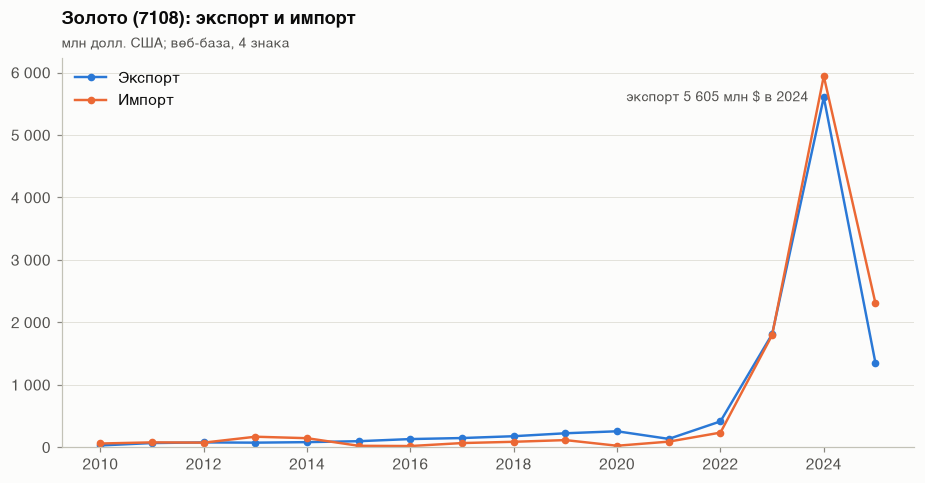

,year,export_musd,import_musd,export_ton,import_ton
0,2010,28.6,60.1,1.6,1.5
1,2011,67.3,78.4,2.3,1.5
2,2012,77.5,74.0,2.3,1.4
3,2013,73.6,168.7,2.8,3.8
4,2014,81.9,145.1,3.6,3.6
5,2015,96.9,23.3,2.9,0.6
6,2016,131.2,19.5,4.0,0.5
7,2017,147.6,67.1,4.5,1.7
8,2018,176.9,87.6,5.0,3.4
9,2019,224.0,114.6,5.8,50.6


In [12]:
gold = sql('''
    SELECT year, export_kusd / 1e3 AS export_musd, import_kusd / 1e3 AS import_musd,
           export_ton, import_ton
    FROM v_db_commodity_annual
    WHERE hs4_code = '7108' AND year BETWEEN 2010 AND 2025
    ORDER BY year
''')

fig, ax = plt.subplots()
for col, name, color in [("export_musd", "Экспорт", SERIES[0]), ("import_musd", "Импорт", SERIES[1])]:
    ax.plot(gold.year, gold[col], color=color, label=name, marker="o", markersize=4)
peak = gold.loc[gold.export_musd.idxmax()]
ax.annotate(f"экспорт {peak.export_musd:,.0f} млн $ в {peak.year:.0f}".replace(",", " "), (peak.year, peak.export_musd),
            xytext=(-10, 0), textcoords="offset points", color=INK2, fontsize=9, va="center", ha="right")
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0)
title(ax, "Золото (7108): экспорт и импорт", "млн долл. США; веб-база, 4 знака")
ax.legend(loc="upper left")
plt.show()

gold

### Сезонность: коньяк и спиртные напитки (2208)

Тепловая карта помесячного экспорта позиции 2208 по годам (одна шкала, от светлого к тёмному).

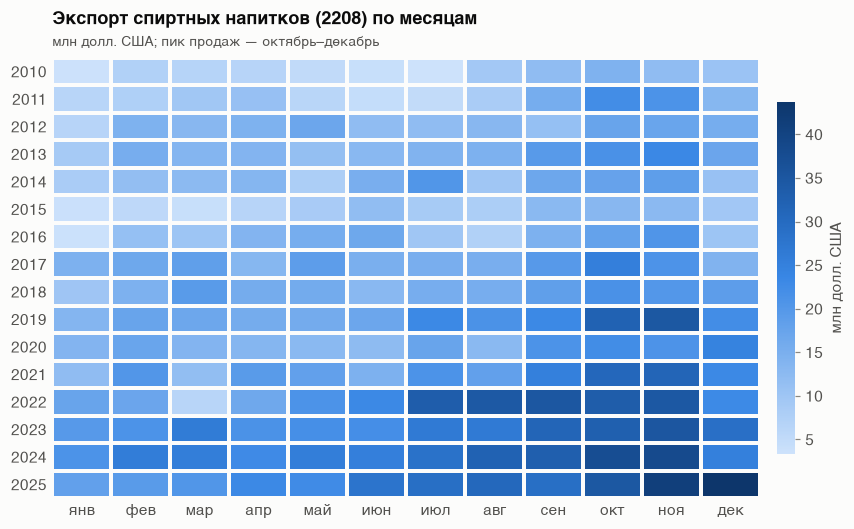

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2010,3.6,7.4,6.7,6.6,5.2,4.2,3.3,9.4,12.1,14.4,12.2,10.6
2011,6.4,7.6,9.7,11.2,6.3,4.6,5.0,8.5,15.6,22.2,21.0,13.3
2012,6.6,14.5,13.2,14.4,17.0,12.1,12.1,13.2,11.4,17.4,17.3,15.5
2013,8.9,15.3,13.7,13.8,11.5,13.1,14.1,14.6,19.5,21.4,23.3,17.1
2014,8.4,11.6,12.5,13.6,8.1,15.2,20.5,9.8,16.8,17.8,18.6,11.0
2015,3.9,5.7,4.3,6.5,8.6,11.9,8.7,8.1,12.9,13.2,12.6,9.6
2016,3.7,11.3,10.2,13.9,15.5,16.7,9.8,7.4,14.6,17.9,20.6,10.2
2017,14.6,16.7,18.6,13.3,18.9,15.1,15.2,15.2,19.6,25.3,20.8,14.1
2018,10.0,14.6,19.3,15.7,16.0,13.0,15.4,15.4,18.5,21.4,20.2,18.8


In [13]:
brandy = sql('''
    SELECT year, month, export_kusd / 1e3 AS export_musd
    FROM v_db_commodity_monthly
    WHERE hs4_code = '2208' AND year BETWEEN 2010 AND 2025
''').pivot(index="year", columns="month", values="export_musd")

fig, ax = plt.subplots(figsize=(10, 5.2))
im = ax.pcolormesh(brandy.values, cmap=SEQ, edgecolors=SURFACE, linewidth=1.5)
ax.invert_yaxis()
ax.set_xticks([m + 0.5 for m in range(12)], ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"])
ax.set_yticks([i + 0.5 for i in range(len(brandy.index))], brandy.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
cb.outline.set_visible(False)
cb.set_label("млн долл. США", color=INK2)
title(ax, "Экспорт спиртных напитков (2208) по месяцам", "млн долл. США; пик продаж — октябрь–декабрь")
plt.show()

brandy.round(1)

## 7. Детализация до 10 знаков: легковые автомобили (8703)

10-значные данные есть только в файлах (`v_file_hs10_current`, текущие редакции 2018–2025). Количество указано
в дополнительной единице (`unit_code`, для автомобилей — штуки), поэтому можно посчитать среднюю стоимость единицы.
Наименований 10-значных кодов в источниках нет — для расшифровки используйте ТН ВЭД ЕАЭС.

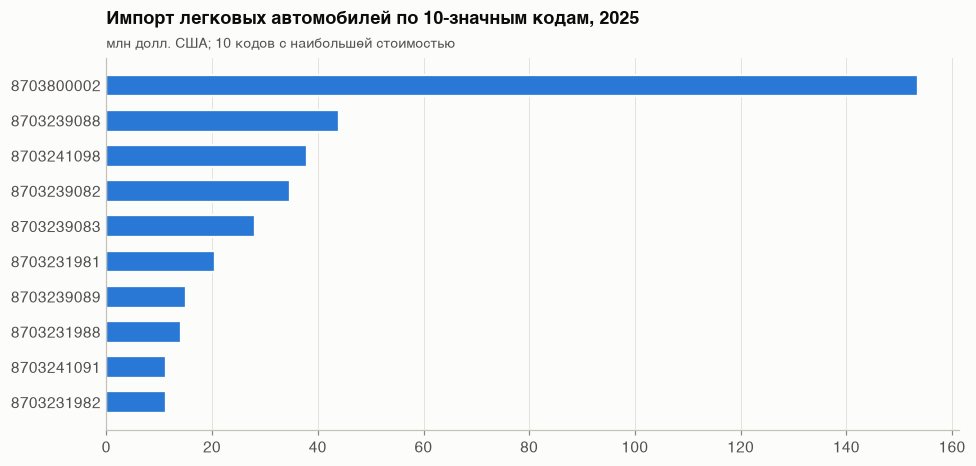

,код,штук,тонн,млн_долл,долл_за_штуку
0,8703800002,6 558.0,12 587.3,153.6,23 419.7
1,8703239088,6 987.0,11 946.5,44.0,6 299.4
2,8703241098,442.0,1 010.5,37.9,85 758.2
3,8703239082,5 460.0,7 970.7,34.7,6 354.2
4,8703239083,4 105.0,5 681.4,28.1,6 855.3
5,8703231981,1 559.0,2 339.8,20.5,13 161.5
6,8703239089,2 057.0,3 381.1,15.1,7 330.0
7,8703231988,179.0,420.9,14.1,78 976.6
8,8703241091,91.0,231.4,11.3,124 643.2
9,8703231982,711.0,1 154.0,11.3,15 952.8


In [14]:
cars = sql('''
    SELECT hs10_code AS код, quantity AS штук, weight_ton AS тонн, value_usd / 1e6 AS млн_долл,
           value_usd / nullif(quantity, 0) AS долл_за_штуку
    FROM v_file_hs10_current
    WHERE year = 2025 AND hs4_code = '8703' AND flow = 'import'
    ORDER BY value_usd DESC LIMIT 10
''')

fig, ax = plt.subplots(figsize=(10, 4.4))
d = cars.iloc[::-1]
ax.barh(d["код"], d["млн_долл"], height=0.62, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
title(ax, "Импорт легковых автомобилей по 10-значным кодам, 2025", "млн долл. США; 10 кодов с наибольшей стоимостью")
plt.show()

cars

In [15]:
# Сколько автомобилей ввезено и по какой средней цене — по годам (все коды 8703, текущие редакции)
sql('''
    SELECT year AS год, sum(quantity) AS штук, sum(value_usd) / 1e6 AS млн_долл,
           sum(value_usd) / sum(quantity) AS средняя_цена_долл
    FROM v_file_hs10_current
    WHERE hs4_code = '8703' AND flow = 'import' AND unit_code = 'piece'
    GROUP BY year ORDER BY year
''')

,год,штук,млн_долл,средняя_цена_долл
0,2018,10 692.0,89.8,8 395.6
1,2019,33 200.0,125.6,3 782.6
2,2020,6 270.0,60.6,9 669.9
3,2021,7 362.0,104.6,14 204.5
4,2022,42 293.0,599.5,14 174.7
5,2023,75 767.0,1 069.3,14 112.9
6,2024,19 383.0,296.8,15 311.6
7,2025,35 554.0,441.0,12 403.1


## 8. Группы ТН ВЭД × партнёры: ЕАЭС и ЕС (бюллетень 2024 г.)

Листы бюллетеня по 2-значным группам дают структуру торговли с группами стран и отдельными странами
(`v_file_hs2_partner_current`), в трёх показателях: тонны, млн драмов и тыс. долл.

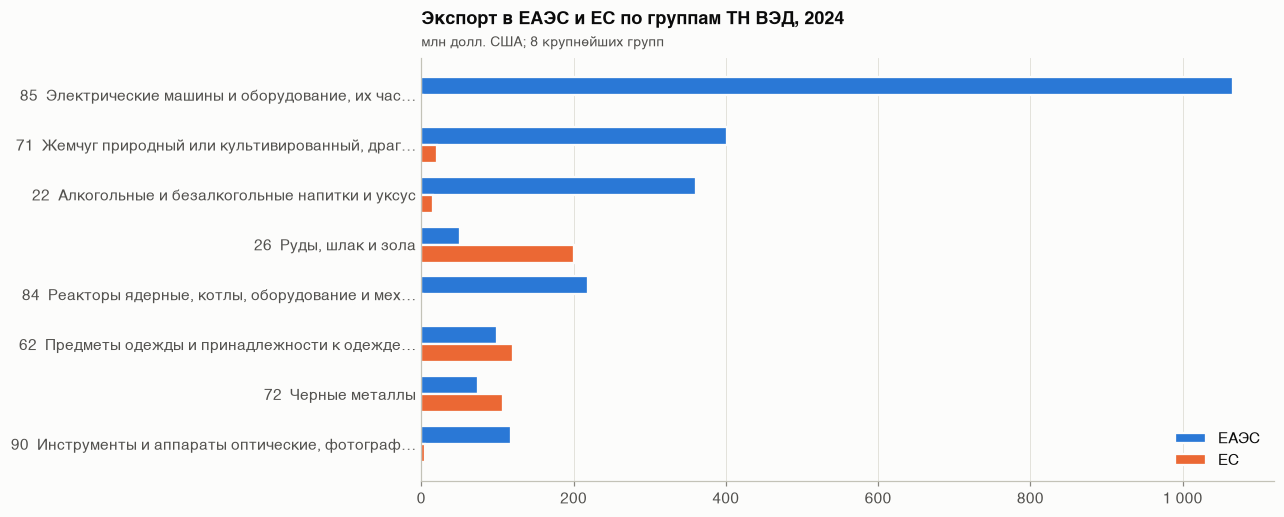

,группа,название,ЕАЭС,ЕС
0,85,"Электрические машины и оборудование, их части; звукозаписывающая и звуковосп...",1 066.3,1.8
1,71,"Жемчуг природный или культивированный, драгоценные или полудрагоценные камни...",401.9,20.2
2,22,Алкогольные и безалкогольные напитки и уксус,360.4,15.2
3,26,"Руды, шлак и зола",50.2,200.9
4,84,"Реакторы ядерные, котлы, оборудование и механические устройства; их части",218.8,1.8
5,62,"Предметы одежды и принадлежности к одежде, кроме трикотажных машинного или р...",99.3,120.0
6,72,Черные металлы,73.9,107.2
7,90,"Инструменты и аппараты оптические, фотографические, кинематографические, изм...",117.4,4.7


In [16]:
groups = sql('''
    SELECT hs2_code AS группа, hs2_name_ru AS название,
           sum(value_kusd) FILTER (WHERE group_code = 'EEU') / 1e3 AS "ЕАЭС",
           sum(value_kusd) FILTER (WHERE group_code = 'EU') / 1e3  AS "ЕС"
    FROM v_file_hs2_partner_current
    WHERE year = 2024 AND flow = 'export' AND partner_kind = 'group' AND group_code IN ('EEU', 'EU')
    GROUP BY ALL
    ORDER BY coalesce("ЕАЭС", 0) + coalesce("ЕС", 0) DESC
    LIMIT 8
''')

fig, ax = plt.subplots(figsize=(10, 5))
d = groups.iloc[::-1].reset_index(drop=True)
h = 0.36
ax.barh([i + h / 2 for i in d.index], d["ЕАЭС"], height=h, color=SERIES[0], label="ЕАЭС", edgecolor=SURFACE, linewidth=1.5)
ax.barh([i - h / 2 for i in d.index], d["ЕС"], height=h, color=SERIES[1], label="ЕС", edgecolor=SURFACE, linewidth=1.5)
ax.set_yticks(d.index, [f"{g}  {short(n, 44)}" for g, n in zip(d["группа"], d["название"])])
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.xaxis.set_major_formatter(thousands)
title(ax, "Экспорт в ЕАЭС и ЕС по группам ТН ВЭД, 2024", "млн долл. США; 8 крупнейших групп")
ax.legend(loc="lower right")
plt.show()

groups

## 9. Сравнение источников

### Веб-база и файлы

Годовые итоги 4-значных файлов (основа «всего», текущие редакции) против веб-базы — проверка `qc_file_vs_db_hs4`.

In [17]:
sql("SELECT * FROM qc_file_vs_db_hs4 ORDER BY year, flow")

,year,flow,file_kusd,db_kusd,diff_pct
0,2018,export,2 412 790.2,2 412 790.2,-0.0
1,2018,import,4 975 217.2,4 975 217.2,-0.0
2,2019,export,2 647 210.9,2 647 210.9,-0.0
3,2019,import,5 528 690.6,5 528 690.6,-0.0
4,2020,export,2 536 974.1,2 536 974.1,-0.0
5,2020,import,4 564 032.3,4 564 032.3,-0.0
6,2021,export,3 015 928.8,3 015 987.2,-0.0
7,2021,import,5 362 204.5,5 362 209.0,-0.0
8,2022,export,5 419 064.5,5 419 064.5,-0.0
9,2022,import,8 775 859.2,8 775 859.2,-0.0


### Ревизии: один год в разных публикациях

Бюллетени по 2-значным группам повторяют последние 4 года, поэтому экспорт за 2021 г. опубликован
в четырёх бюллетенях. Сравним их с веб-базой.

In [18]:
sql('''
    SELECT 'бюллетень ' || w.year AS источник, t.workbook_id, t.value_kusd AS экспорт_тыс_долл
    FROM file_country_trade t JOIN meta_workbook w USING (workbook_id)
    WHERE t.year = 2021 AND t.row_type = 'group' AND t.group_code = 'WORLD' AND t.flow = 'export'
    UNION ALL
    SELECT 'веб-база (nid ' || source_nid || ')', NULL, sum(value_kusd)
    FROM db_country_trade WHERE year = 2021 AND month IS NULL AND flow = 'export' GROUP BY source_nid
    ORDER BY источник
''')

,источник,workbook_id,экспорт_тыс_долл
0,бюллетень 2021,99534448,3 015 987.2
1,бюллетень 2022,99541793,3 015 987.2
2,бюллетень 2023,99563883,3 015 987.2
3,бюллетень 2024,99563888,3 015 987.2
4,веб-база (nid 717),NaN,3 015 987.2


### Доля торговли физических лиц

4-значные файлы делят торговлю на три основы: всего, товарные декларации и декларации физических лиц
(`basis`). Доля физлиц невелика, но в отдельные годы заметна в импорте.

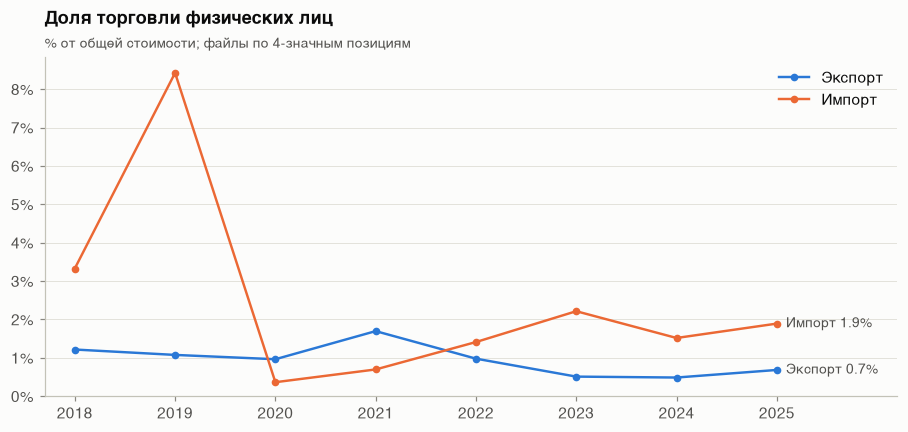

,year,Экспорт,Импорт
0,2018,1.2,3.3
1,2019,1.1,8.4
2,2020,1.0,0.4
3,2021,1.7,0.7
4,2022,1.0,1.4
5,2023,0.5,2.2
6,2024,0.5,1.5
7,2025,0.7,1.9


In [19]:
pp = sql('''
    SELECT year,
           100 * sum(value_kusd) FILTER (WHERE basis = 'physical_persons' AND flow = 'export')
               / sum(value_kusd) FILTER (WHERE basis = 'total' AND flow = 'export') AS "Экспорт",
           100 * sum(value_kusd) FILTER (WHERE basis = 'physical_persons' AND flow = 'import')
               / sum(value_kusd) FILTER (WHERE basis = 'total' AND flow = 'import') AS "Импорт"
    FROM v_file_hs4_current GROUP BY year ORDER BY year
''')

fig, ax = plt.subplots(figsize=(10, 4))
for (name, color) in zip(["Экспорт", "Импорт"], SERIES):
    ax.plot(pp.year, pp[name], color=color, label=name, marker="o", markersize=4)
    end_label(ax, pp.year.iloc[-1], pp[name].iloc[-1], f"{name} {pp[name].iloc[-1]:.1f}%")
ax.set_xlim(pp.year.min() - 0.3, pp.year.max() + 1.2)
ax.set_xticks(pp.year)
ax.set_ylim(0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
title(ax, "Доля торговли физических лиц", "% от общей стоимости; файлы по 4-значным позициям")
ax.legend(loc="upper right")
plt.show()

pp.round(2)

## 10. Гуманитарная помощь (бюллетень 2024 г.)

In [20]:
sql('''
    SELECT c.name_ru AS страна_донор, sum(h.weight_ton) AS тонн, sum(h.value_usd) AS стоимость
    FROM file_humanitarian_aid h
    JOIN meta_workbook w USING (workbook_id)
    LEFT JOIN dim_country c USING (country_code)
    WHERE w.is_current AND w.year = 2024 AND h.row_type = 'country'
    GROUP BY ALL ORDER BY стоимость DESC LIMIT 10
''')

,страна_донор,тонн,стоимость
0,США,73.1,44 733.9
1,Германия,65.7,8 278.8
2,Соедененное Королевство,70.6,5 785.6
3,"Иран, Исламская Республика",152.7,4 907.4
4,Франция,56.3,3 767.6
5,Швейцария,0.1,3 228.0
6,Китай,323.2,3 153.4
7,Италия,27.9,2 387.0
8,Индия,6.6,1 890.5
9,Нидерланды,43.1,1 438.6


Стоимость в листе «Hum-Aid» подписана как «US $», но по порядку величин похожа на тыс. долл. —
см. [data_quality.md](data_quality.md).

## 11. Проверка по исходной ячейке

Любое значение структурированных таблиц можно найти в исходном файле: факты хранят `workbook_id` и `row_num`,
а `raw_xlsx_cell` — все непустые ячейки.

In [21]:
sql('''
    SELECT f.year, f.basis, f.hs4_code, f.flow, f.value_kusd, c.sheet, c.cell_ref, c.value_text
    FROM file_hs4_trade f
    JOIN raw_xlsx_cell c ON c.workbook_id = f.workbook_id AND c.sheet = f.sheet AND c.row_num = f.row_num
    WHERE f.hs4_code = '2208' AND f.year = 2024 AND f.basis = 'total' AND f.flow = 'export'
    ORDER BY c.col_num
''')

,year,basis,hs4_code,flow,value_kusd,sheet,cell_ref,value_text
0,2024,total,2208,export,341 092.8,Sheet1,A184,2208.0
1,2024,total,2208,export,341 092.8,Sheet1,B184,"Էթիլային սպիրտ չբնափոխված, սպիրտի 80%-ից պակաս խտությամբ ըմպելիքներ, լիկյորն..."
2,2024,total,2208,export,341 092.8,Sheet1,C184,121631.886
3,2024,total,2208,export,341 092.8,Sheet1,D184,341092.819
4,2024,total,2208,export,341 092.8,Sheet1,E184,21669.125
5,2024,total,2208,export,341 092.8,Sheet1,F184,72396.989
6,2024,total,2208,export,341 092.8,Sheet1,G184,"Liqueur, spirits and undenatured ethyl alcohol <80%"


In [22]:
# Та же строка веб-базы во всех трёх языковых версиях выгрузки
sql('''
    SELECT lang, nid, country_name, export_kusd, import_origin_kusd, import_consignment_kusd
    FROM stg_db_country
    WHERE mode = 'annual' AND year = 2024 AND country_code = 643
    ORDER BY nid, lang
''')

,lang,nid,country_name,export_kusd,import_origin_kusd,import_consignment_kusd
0,en,159,Russian Federation,3 182 763.1,9 239 977.8,9 432 641.5
1,hy,159,Ռուսաստանի Դաշնություն,3 182 763.1,9 239 977.8,9 432 641.5
2,ru,159,Россия,3 182 763.1,9 239 977.8,9 432 641.5
3,en,717,Russian Federation,3 182 763.1,9 239 977.8,9 432 641.5
4,hy,717,Ռուսաստանի Դաշնություն,3 182 763.1,9 239 977.8,9 432 641.5
5,ru,717,Россия,3 182 763.1,9 239 977.8,9 432 641.5


## 12. Проверки качества

In [23]:
sql("SELECT * FROM qc_summary")

,check_name,status,n_issues,details
0,db_country_159_vs_717,OK,0,rows that differ between the two country pages in overlapping years
1,db_language_consistency,OK,0,queries where languages differ in row count or totals
2,country_names_resolved,OK,0,country labels that could not be matched to dim_country (see qc_unresolved_c...
3,db_country_rows_without_code,OK,0,web database rows whose country name was not resolved
4,db_monthly_vs_annual,INFO,0,complete years where the sum of months differs from the annual value by more...
5,file_totals_vs_items,INFO,2,sheets/sections where the published total differs from the sum of items by m...
6,file_vs_db_hs4,INFO,0,years/flows where 4-digit files and the web database differ by more than 0.5%
7,hs_codes_in_dim,OK,0,distinct hs codes in fact tables missing from dim_hs
8,hs4_rows_without_code,OK,0,item rows of the 4-digit files with an empty code cell
9,partner_rows_without_country,OK,0,rows of country blocks in the 2-digit bulletins without a resolved country code


In [24]:
con.close()